<a href="https://colab.research.google.com/github/ishika-0706/fasta-sequence-orf-analyzer/blob/main/fasta_sequence_orf_analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Install Biopython & Parse Multi-FASTA Records

In [18]:
!pip install biopython pandas matplotlib seaborn -q

from Bio import SeqIO
import pandas as pd

records = list(SeqIO.parse("sequence.fasta", "fasta"))
print(f"Loaded {len(records)} sequences:\n")

for rec in records:
    print(f"ID: {rec.id} | Length: {len(rec.seq)} bp | Description: {rec.description[:60]}...")

Loaded 3 sequences:

ID: NC_000017.11:c7687490-7668421 | Length: 19070 bp | Description: NC_000017.11:c7687490-7668421 Homo sapiens chromosome 17, GR...
ID: NC_086028.1:54798882-54810300 | Length: 11419 bp | Description: NC_086028.1:54798882-54810300 Rattus norvegicus strain BN/NH...
ID: NC_141025.1:25128576-25140154 | Length: 11579 bp | Description: NC_141025.1:25128576-25140154 Danio rerio strain M-AB ecotyp...


# Nucleotide Composition & GC-Content Analysis

,Sequence_ID,Length_bp,A_count,T_count,G_count,C_count,GC_Percent
0,NC_000017.11:c7687490-7668421,19070,4966,4688,4778,4638,49.38
1,NC_086028.1:54798882-54810300,11419,2936,3077,2737,2669,47.34
2,NC_141025.1:25128576-25140154,11579,3372,4035,2177,1995,36.03


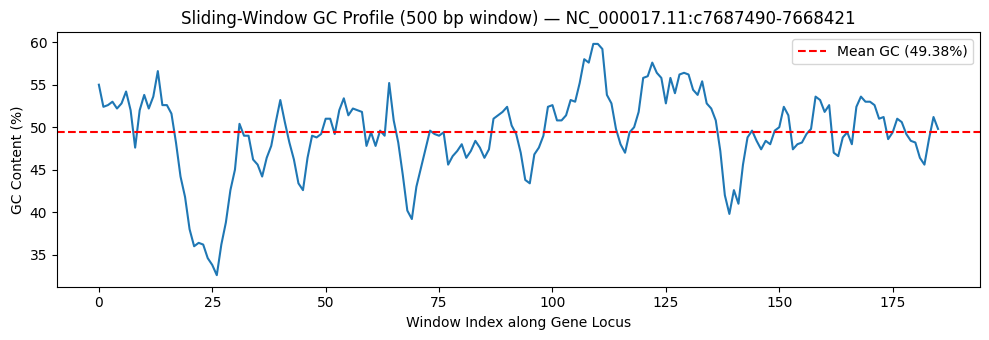

In [19]:
from Bio.SeqUtils import gc_fraction
import matplotlib.pyplot as plt

stats = []
for rec in records:
    seq_str = str(rec.seq).upper()
    stats.append({
        "Sequence_ID": rec.id,
        "Length_bp": len(seq_str),
        "A_count": seq_str.count("A"),
        "T_count": seq_str.count("T"),
        "G_count": seq_str.count("G"),
        "C_count": seq_str.count("C"),
        "GC_Percent": round(gc_fraction(rec.seq) * 100, 2)
    })

df_stats = pd.DataFrame(stats)
display(df_stats)

window_size = 500
gc_windows = [gc_fraction(records[0].seq[i:i+window_size]) * 100
              for i in range(0, len(records[0].seq) - window_size, 100)]

plt.figure(figsize=(10, 3.5))
plt.plot(gc_windows, color="#1f77b4", linewidth=1.5)
plt.axhline(df_stats.loc[0, "GC_Percent"], color="red", linestyle="--", label="Mean GC (49.38%)")
plt.title(f"Sliding-Window GC Profile (500 bp window) — {records[0].id}")
plt.xlabel("Window Index along Gene Locus")
plt.ylabel("GC Content (%)")
plt.legend()
plt.tight_layout()
plt.show()

*Observation & Evolutionary Context*

Comparative nucleotide profiling across vertebrate TP53 genomic orthologs reveals a distinct GC-content gradient from mammals to teleost fish: Homo sapiens (49.38%, 19,070 bp) and Rattus norvegicus (47.34%, 11,419 bp) exhibit markedly higher GC composition than Danio rerio (36.03%, 11,579 bp). Sliding-window profiling (500 bp window) along the human TP53 locus further highlights localized GC-rich peaks corresponding to conserved exonic coding regions and CpG-dense regulatory elements relative to AT-rich intronic segments.

# Open Reading Frame (ORF) Detection & Protein Translation



In [20]:
def find_orfs_and_translate(seq, min_protein_len=50):

    """
    Scans all three forward reading frames of a nucleotide sequence to detect
    Open Reading Frames (ORFs) initiating at 'ATG' (Methionine) and terminating
    at canonical stop codons (TAA, TAG, TGA).

    Parameters:
        seq (Bio.Seq.Seq): Input DNA nucleotide sequence.
        min_protein_len (int): Minimum amino acid length threshold to filter noise.

    Returns:
        pd.DataFrame: Table containing Reading Frame, AA Length, and Protein Preview.
    """

    orfs = []
    # Check all 3 forward reading frames
    for frame in range(3):
        sub_seq = seq[frame:]
        # Trim trailing 1 or 2 bases so length is a multiple of 3
        trim_len = len(sub_seq) - (len(sub_seq) % 3)
        trans = sub_seq[:trim_len].translate(to_stop=False)
        trans_len = len(trans)
        aa_start = 0
        while aa_start < trans_len:
            aa_end = trans.find("*", aa_start)
            if aa_end == -1:
                aa_end = trans_len
            # Look for Methionine ('M' / ATG) within this segment
            segment = trans[aa_start:aa_end]
            m_pos = segment.find("M")
            if m_pos != -1:
                orf_protein = segment[m_pos:]
                if len(orf_protein) >= min_protein_len:
                    orfs.append({
                        "Frame": frame + 1,
                        "AA_Length": len(orf_protein),
                        "Protein_Preview": str(orf_protein[:30]) + "..."
                    })
            aa_start = aa_end + 1
    return pd.DataFrame(orfs)

# Run on the first sequence
orf_df = find_orfs_and_translate(records[0].seq, min_protein_len=50)
print(f"Detected {len(orf_df)} candidate ORFs (>= 50 aa) in {records[0].id}:")
display(orf_df.head(10))

Detected 18 candidate ORFs (>= 50 aa) in NC_000017.11:c7687490-7668421:


,Frame,AA_Length,Protein_Preview
0,1,118,MPTKSQTLFIVPETFHHVSSQSIPDPTFIL...
1,1,51,MEPCIRWGRVGAKGVSFPIQRLQAENDYIL...
2,1,65,MVLGEGVPSLQAQVTQGWKCLMLDPHFSSC...
3,1,87,MCNSSCMGGMNRRPILTIITLEDSRSGATC...
4,1,58,MISAHCNLCLLGSSDSPASASRIARTTSAC...
5,2,139,MRGEERERKCPLGRFLLLGRGRLLFSACIS...
6,2,91,MFLSKSDDKFGIKKESIPEKKKKKKKESIL...
7,2,134,MDDLMLSPDDIEQWFTEDPGPDEAPRMPEA...
8,2,96,MGQVGPDFLTASCFSFPILSSGNLLGRNSF...
9,2,51,MPRHPANFLFSVKSRSCYVAHAGIKPLGSI...


*Observation & Biological Context*

 Analysis of the human TP53 genomic locus (NC_000017.11:c7687490-7668421, 19,070 bp) reveals an overall GC-content of 49.38% (4,778 G; 4,638 C). Three-frame forward scanning identified 18 candidate Open Reading Frames ($\ge 50\text{ aa}$) spanning up to 139 amino acids. Because this accession represents the unspliced genomic DNA sequence containing intronic regions, full-length canonical p53 (393 aa) spans multiple exons rather than a single contiguous genomic ORF.

# Point Mutation or Variant Comparator

In [22]:
from Bio.Align import PairwiseAligner

def compare_point_mutations(seq1, seq2):
    min_len = min(len(seq1), len(seq2))
    mutations = []
    for i in range(min_len):
        if seq1[i] != seq2[i]:
            mutations.append({
                "Position_1based": i + 1,
                "Ref_Base": seq1[i],
                "Alt_Base": seq2[i]
            })
    return pd.DataFrame(mutations)

if len(records) >= 2:
    mut_df = compare_point_mutations(str(records[0].seq).upper(), str(records[1].seq).upper())
    print(f"Total single-nucleotide differences found: {len(mut_df)}")
    display(mut_df.head(15))

aligner = PairwiseAligner()
aligner.mode = "global"
score = aligner.score(records[0].seq[:2000], records[1].seq[:2000])
print(f"Pairwise Global Alignment Score (first 2000 bp): {score}")

Total single-nucleotide differences found: 8553


,Position_1based,Ref_Base,Alt_Base
0,1,C,A
1,2,T,G
2,3,C,T
3,4,A,T
4,5,A,C
5,7,A,T
6,8,G,T
7,9,T,G
8,10,C,G
9,11,T,G


Pairwise Global Alignment Score (first 2000 bp): 978.0


*Observation & Methodological Note*

Direct index-by-index comparison between Homo sapiens (NC_000017.11, 19,070 bp) and Rattus norvegicus (NC_086028.1, 11,419 bp) TP53 genomic loci yielded 8,553 positional mismatches over the overlapping 11,419 bp window. Because orthologous vertebrate genes undergo species-specific intronic insertions, deletions, and length divergence across evolutionary time, direct positional indexing overestimates point substitutions—demonstrating why global/local sequence alignment (Bio.Align.PairwiseAligner, global alignment score = 978.0 over the first 2,000 bp) is essential prior to cross-species variant calling.